# 05 Correlations and release

1. Correlations among the 55 features on the training addresses, for the released, lifetime, and leakage-resistant sets.
2. The correlation figure, `outputs/figures/corr55.pdf`.
3. The released dataset, `outputs/features/elliptic_pp_leakage_resistant.parquet`.

The released dataset holds the address, its side of the temporal split, and the 55 leakage-resistant features.
It contains no labels, which belong to Elliptic++.

In [1]:
from pathlib import Path
import duckdb
import numpy as np
import pandas as pd

ROOT      = Path.cwd().parent
RAW       = ROOT / 'data' / 'raw'
PROCESSED = ROOT / 'data' / 'processed'
OUTPUTS   = ROOT / 'outputs'
WALLETS   = RAW / 'elliptic_pp' / 'wallets_features_classes_combined.csv'
FEATURES_LIFETIME  = PROCESSED / 'features_lifetime.parquet'
FEATURES_RESISTANT = PROCESSED / 'features_leakage_resistant.parquet'
pd.set_option('display.width', 200)

STATS = ['total', 'min', 'max', 'mean', 'median']
FAMILIES = {
    'Volumes':      [f'btc_{q}_{s}' for q in ['transacted', 'sent', 'received'] for s in STATS],
    'Fees':         [f'fees_{s}' for s in STATS] + [f'fees_as_share_{s}' for s in STATS],
    'Block gaps':   [f'blocks_btwn_{q}_{s}' for q in ['txs', 'input_txs', 'output_txs'] for s in STATS],
    'Counterparty': [f'transacted_w_address_{s}' for s in STATS] + ['num_addr_transacted_multiple'],
    'Counts':       ['total_txs', 'num_txs_as_sender', 'num_txs_as receiver'],
    'Lifetime':     ['first_block_appeared_in', 'last_block_appeared_in', 'lifetime_in_blocks',
                     'first_sent_block', 'first_received_block', 'num_timesteps_appeared_in'],
}
FEATURES = [f for fs in FAMILIES.values() for f in fs]
assert len(FEATURES) == 55

con = duckdb.connect()
released = con.execute(f"""
    SELECT * FROM read_csv('{WALLETS}', header=true) WHERE "class" IN (1, 2)
    QUALIFY ROW_NUMBER() OVER (PARTITION BY address ORDER BY "Time step") = 1
    ORDER BY address""").fetchdf()
lifetime  = pd.read_parquet(FEATURES_LIFETIME).sort_values('address').reset_index(drop=True)
resistant = pd.read_parquet(FEATURES_RESISTANT).sort_values('address').reset_index(drop=True)
print(f'released {len(released):,}  lifetime {len(lifetime):,}  leakage-resistant {len(resistant):,}')

(OUTPUTS / 'figures').mkdir(parents=True, exist_ok=True)
(OUTPUTS / 'features').mkdir(parents=True, exist_ok=True)

train = lifetime.loc[lifetime.split == 'train', 'address']
X = {'released':          released.set_index('address').loc[train, FEATURES].astype(float),
     'lifetime':          lifetime.set_index('address').loc[train, FEATURES].astype(float),
     'leakage-resistant': resistant.set_index('address').loc[train, FEATURES].astype(float)}
R = {(k, method): v.corr(method=method) for k, v in X.items() for method in ['pearson', 'spearman']}
print(f'training addresses {len(train):,}')

released 265,354  lifetime 265,352  leakage-resistant 265,352
training addresses 172,903


## 1. Correlations

Changes between feature sets are taken over all 1,485 feature pairs.

In [2]:
upper = np.triu_indices(55, 1)
rows = []
for method in ['spearman', 'pearson']:
    for a, b in [('leakage-resistant', 'released'), ('lifetime', 'released')]:
        d = np.abs((R[(a, method)] - R[(b, method)]).to_numpy())[upper]
        i = np.nanargmax(d)
        rows.append({'method': method, 'comparison': f'{a} vs {b}', 'max |change|': round(d[i], 3),
                     'pair': f'{FEATURES[upper[0][i]]} x {FEATURES[upper[1][i]]}',
                     'pairs changing by > 0.05': int((d > 0.05).sum())})
print(pd.DataFrame(rows).to_string(index=False))

  method                    comparison  max |change|                                                   pair  pairs changing by > 0.05
spearman leakage-resistant vs released         0.044     last_block_appeared_in x num_timesteps_appeared_in                         0
spearman          lifetime vs released         0.006 transacted_w_address_min x transacted_w_address_median                         0
 pearson leakage-resistant vs released         0.380                           btc_sent_max x btc_sent_mean                       195
 pearson          lifetime vs released         0.013        btc_received_total x transacted_w_address_total                         0


In [3]:
for a, b in [('lifetime_in_blocks', 'blocks_btwn_txs_total'), ('btc_sent_total', 'btc_received_total')]:
    for k in ['released', 'leakage-resistant']:
        print(f"{a} x {b}, {k}: Pearson {R[(k, 'pearson')].loc[a, b]:.3f}, Spearman {R[(k, 'spearman')].loc[a, b]:.3f}")

lifetime_in_blocks x blocks_btwn_txs_total, released: Pearson 1.000, Spearman 1.000
lifetime_in_blocks x blocks_btwn_txs_total, leakage-resistant: Pearson 1.000, Spearman 1.000
btc_sent_total x btc_received_total, released: Pearson 0.877, Spearman -0.354
btc_sent_total x btc_received_total, leakage-resistant: Pearson 0.807, Spearman -0.363


In [4]:
S = R[('released', 'spearman')]
rows = []
for fam, fs in FAMILIES.items():
    for q in dict.fromkeys(f.rsplit('_', 1)[0] for f in fs if f.rsplit('_', 1)[-1] in STATS):
        group = [f'{q}_{s}' for s in STATS]
        if all(g in fs for g in group):
            v = S.loc[group, group].to_numpy()[np.triu_indices(5, 1)]
            rows.append({'quantity': q, 'mean Spearman': round(v.mean(), 3), 'min Spearman': round(v.min(), 3)})
print('Spearman correlations among the five statistics of a quantity, released features')
print(pd.DataFrame(rows).to_string(index=False))

Spearman correlations among the five statistics of a quantity, released features
              quantity  mean Spearman  min Spearman
        btc_transacted          0.989         0.967
              btc_sent          0.881         0.710
          btc_received          0.851         0.621
                  fees          0.940         0.841
         fees_as_share          0.949         0.871
       blocks_btwn_txs          0.971         0.932
 blocks_btwn_input_txs          0.940         0.872
blocks_btwn_output_txs          0.964         0.919
  transacted_w_address          0.496        -0.004


## 2. Figure

One matrix per feature set, Pearson correlations above the diagonal and Spearman correlations below it.

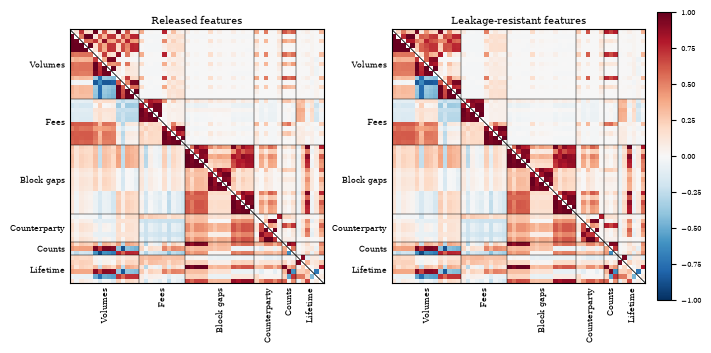

In [5]:
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
plt.rcParams.update({'font.family': 'serif', 'font.serif': ['Linux Libertine O', 'Libertinus Serif', 'DejaVu Serif'],
                     'pdf.fonttype': 42, 'font.size': 7})


def combined(k):
    M = np.full((55, 55), np.nan)
    M[np.triu_indices(55, 1)] = R[(k, 'pearson')].to_numpy()[np.triu_indices(55, 1)]
    M[np.tril_indices(55, -1)] = R[(k, 'spearman')].to_numpy()[np.tril_indices(55, -1)]
    return M


family = [fam for fam, fs in FAMILIES.items() for _ in fs]
edges, ticks, start = [], [], 0
for i in range(1, 56):
    if i == 55 or family[i] != family[start]:
        edges.append(i); ticks.append(((start + i - 1) / 2, family[start])); start = i

fig, axes = plt.subplots(1, 2, figsize=(7.0, 3.6), constrained_layout=True)
cmap = plt.get_cmap('RdBu_r').copy(); cmap.set_bad('white')
for ax, (k, title) in zip(axes, [('released', 'Released features'), ('leakage-resistant', 'Leakage-resistant features')]):
    im = ax.imshow(np.ma.masked_invalid(combined(k)), cmap=cmap, norm=TwoSlopeNorm(0, -1, 1), interpolation='nearest')
    ax.plot([-0.5, 54.5], [-0.5, 54.5], color='black', lw=0.6)
    for e in edges[:-1]:
        ax.axhline(e - 0.5, color='black', lw=0.35); ax.axvline(e - 0.5, color='black', lw=0.35)
    ax.set_xticks([t for t, _ in ticks]); ax.set_xticklabels([n for _, n in ticks], rotation=90, fontsize=6)
    ax.set_yticks([t for t, _ in ticks]); ax.set_yticklabels([n for _, n in ticks], fontsize=6)
    ax.tick_params(length=0)
    ax.set_title(title, fontsize=7, pad=4)
cb = fig.colorbar(im, ax=axes, fraction=0.025, pad=0.02); cb.ax.tick_params(labelsize=5)
fig.savefig(OUTPUTS / 'figures' / 'corr55.pdf', bbox_inches='tight')
plt.show()

## 3. Released dataset

In [6]:
release = resistant[['address', 'split'] + FEATURES].sort_values('address').reset_index(drop=True)
path = OUTPUTS / 'features' / 'elliptic_pp_leakage_resistant.parquet'
release.to_parquet(path, index=False)
print(f'{path.name}: {len(release):,} addresses, {release.shape[1]} columns, {path.stat().st_size / 1e6:.1f} MB')
print(release.split.value_counts().to_string())

elliptic_pp_leakage_resistant.parquet: 265,352 addresses, 57 columns, 48.8 MB
split
train    172903
test      92449


Labels are attached from the user's own copy of the Elliptic++ wallet file. Classes 1 and 2 are illicit and licit.

In [7]:
labels = con.execute(f"""
    SELECT address, MIN("class") AS label FROM read_csv('{WALLETS}', header=true)
    WHERE "class" IN (1, 2) GROUP BY address""").fetchdf()
labelled = release.merge(labels, on='address', how='left')
print(f'addresses with a label: {labelled.label.notna().sum():,} of {len(labelled):,}')

addresses with a label: 265,352 of 265,352
